**1. Entorno y datos de entrenamiento**
Carga el panel verificado y separa de inmediato las filas elegibles de entrenamiento (año objetivo ≤ 2021); prueba 2022–2025 no se usa.

In [1]:
from pathlib import Path
import sys, json, unittest
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/feature_engineering.py').is_file())
sys.path.insert(0, str(ROOT))
import src.ablacion_variables as ab
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_colwidth', 80, 'display.max_rows', 80)
train, cols = ab.cargar_entrenamiento()
print('Filas de entrenamiento:', len(train), '| particiones:', train.particion.unique().tolist(), '| año objetivo máx.:', train.anio_objetivo.max())
display(train.groupby('Moneda').agg(filas=('RPJ', 'size'), empresas=('RPJ', 'nunique'), anio_obj_min=('anio_objetivo', 'min'), anio_obj_max=('anio_objetivo', 'max')))

Filas de entrenamiento: 2869 | particiones: ['entrenamiento'] | año objetivo máx.: 2021


,filas,empresas,anio_obj_min,anio_obj_max
Moneda,,,,
D lares,353,49,2006,2021
Soles,2516,269,2006,2021


Solo quedan las 2.869 filas de entrenamiento (2.516 en soles y 353 en dólares), con años objetivo 2006–2021. La función de carga descarta el resto del panel.

**2. Auditoría de la especificación E2**
Contrasta el Pipeline con el código literal del notebook 07 y verifica que reproduce sus predicciones E2 de entrenamiento.

In [2]:
spec = ab.verificar_modelo_original()
print('Atributos (26) y orden:', cols == spec['E2'], '| alpha original:', spec['alpha'])
print(json.dumps(spec['objetivo'], ensure_ascii=False, indent=1))
print('Diferencia relativa máxima frente a notebook 07:', ab.verificar_replica_sprint06(train, cols))

Atributos (26) y orden: True | alpha original: 1.0
{
 "nombre": "objetivo_fcl_t1",
 "definicion": "FCL_preliminar(t+1) = FCO(t+1) + CAPEX_reportado(t+1) de la misma RPJ, unido por Ejercicio+1 exacto (nunca la fila siguiente); faltante si CAPEX_reportado(t+1) > 0. FCL preliminar, no FCFF validado.",
 "horizonte": "un ejercicio anual adelante (anio_objetivo = Ejercicio + 1)",
 "elegibilidad": "utilizable_supervisado = objetivo no faltante Y Moneda(t) == Moneda(t+1); sin imputación del objetivo",
 "particion": "entrenamiento: anio_objetivo <= 2021 (Ejercicio 2005–2020); prueba: anio_objetivo 2022–2025 (Ejercicio 2021–2024)"
}
Diferencia relativa máxima frente a notebook 07: {'D lares': 0.0, 'Soles': 0.0}


Coinciden los atributos, el objetivo t+1 por unión exacta, la elegibilidad, las particiones y la preparación. La réplica es exacta (diferencia 0). Las inconsistencias documentadas son el RobustScaler de `make_preprocessor` (no es E2), el recorte y los niveles de Sprint 06 (no son E2) y la etiqueta `D lares`. Ninguna cambia la especificación usada.

**3. Protocolos declarados antes de ejecutar**
Validación anidada (principal) y diagnóstico individual: cortes, rejilla de alpha, reglas de aceptación, desempates y máximo de pasos.

In [3]:
cfg = ab.configuracion(cols, spec)
cfg['validacion_anidada'] = ab.protocolo_anidado()
print(json.dumps(cfg['validacion_anidada'], ensure_ascii=False, indent=1))

{
 "proposito": "Estimar el desempeño de un procedimiento de selección (atributos y alpha) frente al modelo completo con alpha seleccionado, separando selección (validación interna, solo pasado) y evaluación (año externo no usado en decisiones).",
 "anios_externos": [
  2017,
  2018,
  2019,
  2020,
  2021
 ],
 "entrenamiento_externo": "todas las filas con anio_objetivo < año externo, misma moneda",
 "validacion_interna": "los 3 años objetivo inmediatamente anteriores al año externo; cada uno con ventana expansiva (entrena con años anteriores) y al menos 8 años de historia; por eso el primer año externo es 2017",
 "compatibilidad_sprint06": "Se conserva la unidad año objetivo, las ventanas expansivas y el calentamiento de 8 años de Sprint 06. Sus bloques de 2 años no se reutilizan como pliegues externos porque los primeros (2014–2015) no dejan historia para una validación interna.",
 "rejilla_alpha": [
  0.1,
  1.0,
  10.0,
  100.0,
  1000.0,
  10000.0
 ],
 "seleccion_alpha": "mínimo R

Años externos 2017–2021, cada uno con 3 años internos previos y al menos 8 años de historia. La rejilla de alpha es la de Sprint 06. Una retirada se acepta si mejora el RMSE interno ≥ 1 % en ≥ 2 de 3 años, con un máximo de 5. Reducir solo se recomienda si mejora ≥ 1 % en ≥ 4 de 5 años externos.

**4. Ejecución completa**
`run()` calcula la validación anidada, la lista final propuesta y el diagnóstico individual, y escribe `reports/sprint_08/ablacion/`.

In [4]:
salidas = ab.run()
display(salidas['anidada_pliegues_externos.csv'])

,moneda,anio_externo,n_train,empresas_train,n_externo,empresas_externo,alpha_completo,alpha_reducido,n_atributos_reducido,retirados
0,D lares,2017,234,43,21,21,10000.0,1000.0,24,FCO_lag1;FCL_preliminar_lag1
1,D lares,2018,255,43,25,25,1000.0,1000.0,26,
2,D lares,2019,280,47,26,26,1000.0,1000.0,24,FCL_preliminar_lag1;FCL_preliminar_lag2
3,D lares,2020,306,48,24,24,1000.0,1000.0,26,
4,D lares,2021,330,48,23,23,1000.0,1000.0,25,crecimiento_TotalIngreso
5,Soles,2017,1687,246,177,177,10000.0,10000.0,26,
6,Soles,2018,1864,256,169,169,10000.0,10000.0,26,
7,Soles,2019,2033,261,162,162,10000.0,10000.0,23,fco_activo;FCO_std3_previa;FCL_preliminar_std3_previa
8,Soles,2020,2195,263,161,161,10000.0,10000.0,26,
9,Soles,2021,2356,264,160,160,10000.0,10000.0,26,


Cada año externo se predice con un modelo entrenado solo con los años anteriores. Dólares entrena con 234–330 filas y evalúa 21–26 por año; soles entrena con 1.687–2.356 y evalúa 160–177.

**5. Parte A: desempeño externo por año y procedimiento**
RMSE y MAE por año externo del completo con alpha interno, el reducido y E2 con alpha = 1 (contexto).

In [5]:
anual = salidas['anidada_metricas_por_anio.csv']
display(anual.pivot_table(index=['moneda', 'anio_externo'], columns='procedimiento', values=['RMSE', 'MAE']).round(0))
display(salidas['anidada_comparaciones_pareadas.csv'][['procedimiento', 'moneda', 'anio_externo', 'delta_RMSE', 'delta_RMSE_pct', 'delta_MAE_pct', 'direccion_RMSE']].round(2))

MAE                                        RMSE                                  
procedimiento        E2_alpha_1 completo_alpha_interno  reducido E2_alpha_1 completo_alpha_interno   reducido
moneda  anio_externo                                                                                         
D lares 2017           159686.0               151119.0  141405.0   395387.0               324072.0   289047.0
        2018           247599.0                63925.0   63925.0   642303.0                94176.0    94176.0
        2019           154374.0                90918.0   91484.0   289417.0               152629.0   153449.0
        2020           149611.0               110204.0  110204.0   279754.0               220363.0   220363.0
        2021           309612.0               226683.0  226784.0   435940.0               448183.0   448461.0
Soles   2017           216075.0               172227.0  172227.0   759286.0               657506.0   657506.0
        2018           449239.0               137993.0  137993.0  3930776.0               376567.0   376567.0
        2019           199453.0               203034.0  208764.0   662154.0               637089.0   669818.0
        2020           327222.0               395824.0  395824.0  1580257.0              1731841.0  1731841.0
        2021           405547.0               360244.0  360244.0  1277368.0              1190774.0  1190774.0

,procedimiento,moneda,anio_externo,delta_RMSE,delta_RMSE_pct,delta_MAE_pct,direccion_RMSE
0,E2_alpha_1,D lares,2017,71315.03,22.01,5.67,empeora
1,E2_alpha_1,D lares,2018,548126.73,582.02,287.33,empeora
2,E2_alpha_1,D lares,2019,136788.20,89.62,69.79,empeora
3,E2_alpha_1,D lares,2020,59391.30,26.95,35.76,empeora
4,E2_alpha_1,D lares,2021,-12242.91,-2.73,36.58,mejora
5,E2_alpha_1,Soles,2017,101779.72,15.48,25.46,empeora
6,E2_alpha_1,Soles,2018,3554208.68,943.84,225.55,empeora
7,E2_alpha_1,Soles,2019,25065.12,3.93,-1.76,empeora
8,E2_alpha_1,Soles,2020,-151584.09,-8.75,-17.33,mejora
9,E2_alpha_1,Soles,2021,86593.89,7.27,12.58,empeora


El reducido coincide con el completo en los años en que no retira nada. Difiere en 2017 (dólares, −10,8 %), en 2019 (dólares +0,5 %, soles +5,1 %) y en 2021 (dólares +0,06 %). E2 con alpha = 1 empeora mucho en casi todos los años, sobre todo en 2018 en ambas monedas.

**6. Parte A: resumen y recomendación por moneda**
Promedio de métricas anuales (igual peso por año), métricas concatenadas, años con mejora y peor empeoramiento anual.

In [6]:
res_a = salidas['anidada_resumen.csv']
display(res_a.set_index(['moneda', 'procedimiento']).drop(columns=['n_externo']).round(2).T)

moneda,D lares,Soles,D lares,Soles,D lares,Soles
procedimiento,E2_alpha_1,E2_alpha_1,completo_alpha_interno,completo_alpha_interno,reducido,reducido
anios_externos,5,5,5,5,5,5
RMSE_anual_medio,408560.28,1641968.15,247884.6,918755.49,241099.4,925301.31
MAE_anual_medio,204176.48,319507.24,128570.15,253864.38,126760.54,255010.44
RMSE_concatenado,430203.21,2039243.7,272219.09,1027951.36,265361.6,1032009.06
MAE_concatenado,203939.96,318514.29,126001.16,250980.94,124429.91,252100.74
delta_RMSE_anual_medio_pct,64.82,78.72,NaN,NaN,-2.74,0.71
delta_MAE_anual_medio_pct,58.81,25.86,NaN,NaN,-1.41,0.45
delta_RMSE_concatenado_pct,58.04,98.38,NaN,NaN,-2.52,0.39
delta_MAE_concatenado_pct,61.86,26.91,NaN,NaN,-1.25,0.45


Dólares: el reducido cambia el RMSE anual medio −2,74 %, pero mejora en solo 1 de 5 años. La regla da "evidencia insuficiente". Soles: +0,71 % y ningún año mejor, así que la regla da "conservar el modelo completo". Las métricas concatenadas van en la misma dirección.

**7. Parte A: historial de selección, frecuencias y alpha**
Retiradas aceptadas en cada pliegue externo, frecuencia de retirada por atributo y regularización elegida.

In [7]:
h = salidas['anidada_historial_seleccion.csv']
display(h.loc[h.elegido, ['moneda', 'anio_externo', 'paso', 'atributo_evaluado', 'alpha', 'rmse_interno_medio', 'mejora_pct', 'anios_internos_mejora', 'aceptado', 'motivo']].round(2))
f = salidas['anidada_frecuencia_retirada.csv']
display(f.loc[f.veces_retirado.gt(0)])
display(salidas['anidada_frecuencia_alpha.csv'])
display(salidas['anidada_lista_final_propuesta.csv'])

,moneda,anio_externo,paso,atributo_evaluado,alpha,rmse_interno_medio,mejora_pct,anios_internos_mejora,aceptado,motivo
0,D lares,2017,0,,10000.0,277139.93,NaN,NaN,True,punto de partida: 26 atributos
16,D lares,2017,1,FCL_preliminar_lag1,1000.0,272580.90,1.65,3.0,True,retirada aceptada
37,D lares,2017,2,FCO_lag1,1000.0,268458.25,1.51,3.0,True,retirada aceptada
62,D lares,2017,3,FCO_lag2,100.0,266989.65,0.55,2.0,False,"no aceptada: mejora 0.55 % (mínimo 1 %), años internos con mejora 2 (mínimo 2)"
76,D lares,2018,0,,1000.0,271792.07,NaN,NaN,True,punto de partida: 26 atributos
92,D lares,2018,1,FCL_preliminar_lag1,100.0,255838.05,5.87,1.0,False,"no aceptada: mejora 5.87 % (mínimo 1 %), años internos con mejora 1 (mínimo 2)"
103,D lares,2019,0,,1000.0,179519.44,NaN,NaN,True,punto de partida: 26 atributos
119,D lares,2019,1,FCL_preliminar_lag1,1000.0,166884.14,7.04,2.0,True,retirada aceptada
145,D lares,2019,2,FCL_preliminar_lag2,1000.0,160132.76,4.05,2.0,True,retirada aceptada
165,D lares,2019,3,FCO_lag1,100.0,158012.78,1.32,1.0,False,"no aceptada: mejora 1.32 % (mínimo 1 %), años internos con mejora 1 (mínimo 2)"


,moneda,atributo,veces_retirado,pliegues,anios_externos_retirado
8,D lares,crecimiento_TotalIngreso,1,5,2021
10,D lares,FCO_lag1,1,5,2017
15,D lares,FCL_preliminar_lag1,2,5,2017;2019
16,D lares,FCL_preliminar_lag2,1,5,2019
30,Soles,fco_activo,1,5,2019
39,Soles,FCO_std3_previa,1,5,2019
44,Soles,FCL_preliminar_std3_previa,1,5,2019


,moneda,procedimiento,alpha,pliegues
0,D lares,completo_alpha_interno,1000.0,4
1,D lares,completo_alpha_interno,10000.0,1
2,D lares,reducido,1000.0,5
3,Soles,completo_alpha_interno,10000.0,5
4,Soles,reducido,10000.0,5


,moneda,anios_internos,n_train,alpha_completo,alpha_reducido,n_atributos,retirados,estado
0,D lares,2019;2020;2021,353,1000.0,1000.0,25,crecimiento_pbi_real_pct,Propuesta pendiente de evaluación posterior; sin métricas externas propias
1,Soles,2019;2020;2021,2516,1000.0,1000.0,26,,Propuesta pendiente de evaluación posterior; sin métricas externas propias


Ningún atributo se retira en más de 2 de 5 pliegues; el más frecuente es `FCL_preliminar_lag1` en dólares (2017 y 2019). El procedimiento no retira nada en 2 de 5 pliegues en dólares y en 4 de 5 en soles. En soles, alpha queda en 10000, el máximo de la rejilla, en las 10 selecciones. La lista final propuesta retira `crecimiento_pbi_real_pct` en dólares y nada en soles; está pendiente de evaluación posterior y no tiene métricas externas propias.

**8. Parte A: gráficos**
RMSE por año externo de los tres procedimientos y atributos retirados en cada pliegue.

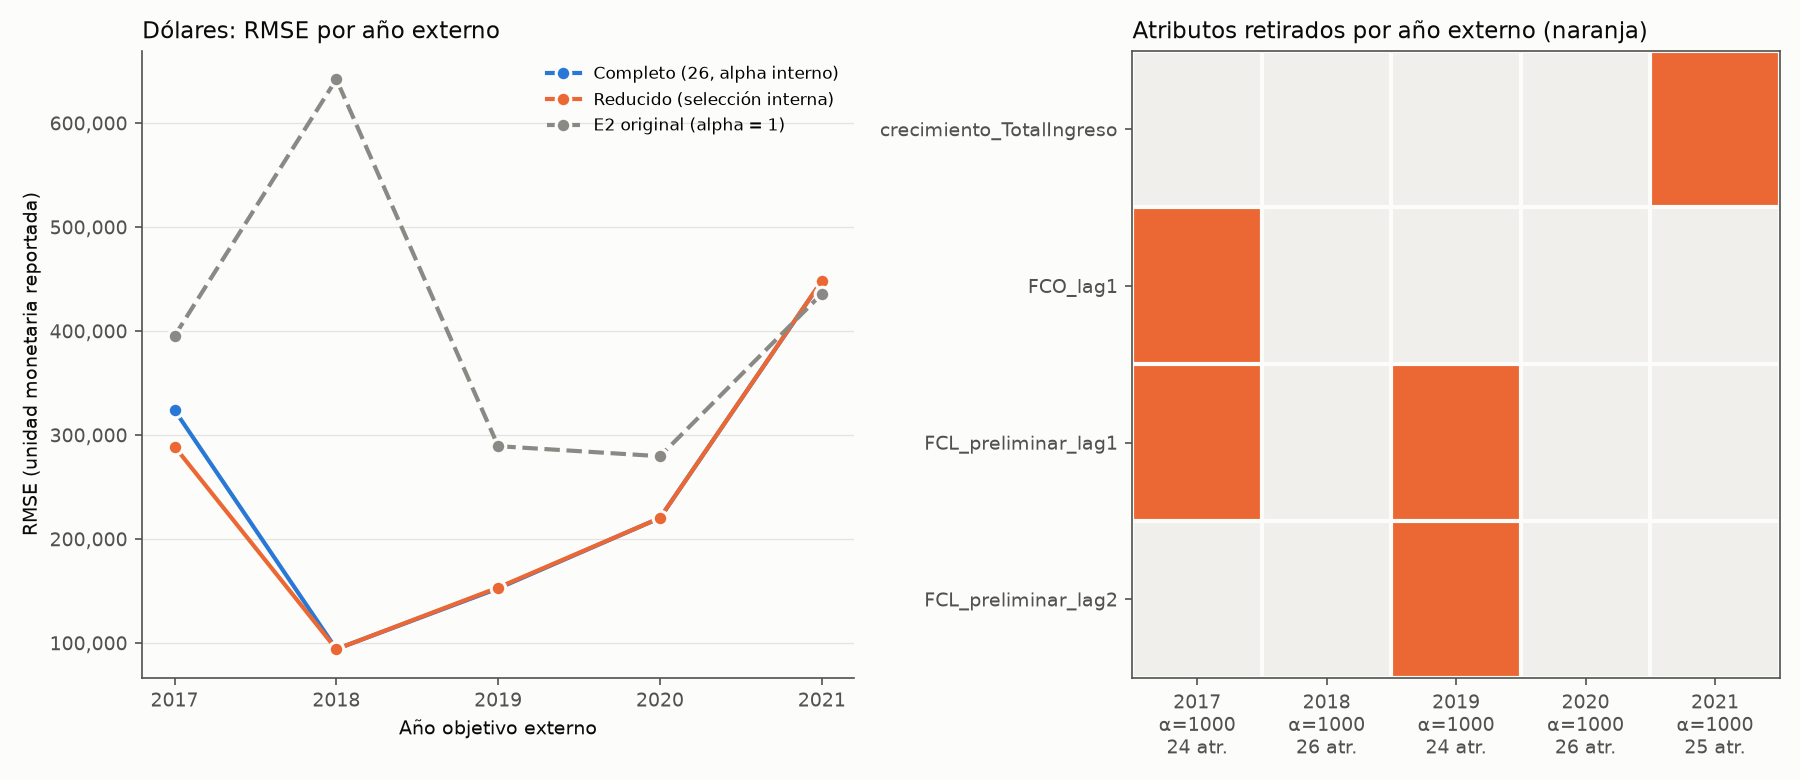

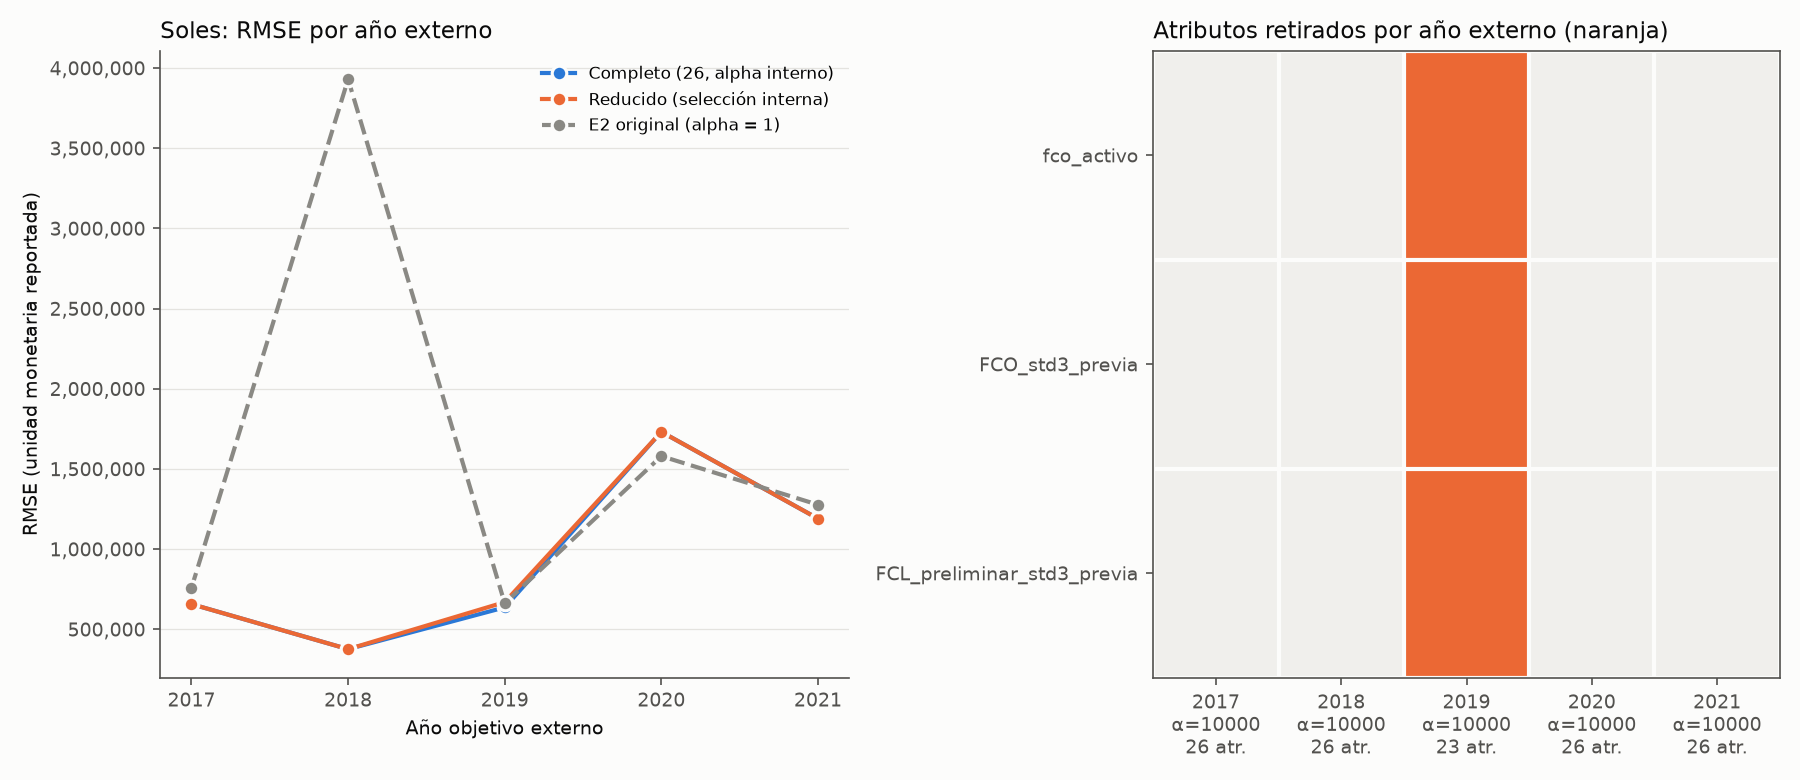

In [8]:
for m in ['dolares', 'soles']:
    display(Image(filename=str(ab.OUT / 'graficos' / f'anidada_{m}.png'), width=900))

La diferencia entre el completo y el reducido es pequeña frente a la que hay entre cualquiera de ellos y E2 con alpha = 1. La regularización pesa más que la retirada de variables.

**9. Parte B: diagnóstico de ablación individual (Ridge con alpha = 1)**
Efecto de retirar cada atributo del E2 original en los pliegues de Sprint 06; diagnóstico condicionado, no selección definitiva.

In [9]:
res = salidas['resumen_ablacion.csv']
columnas = ['atributo_retirado', 'delta_RMSE_medio_pct', 'delta_MAE_medio_pct', 'mediana_delta_RMSE_anual_pct', 'anios_mejora_RMSE', 'anios_empeora_RMSE',
            'clasificacion', 'candidata_robusta_a_casos_dominantes']
for moneda, g in res.groupby('moneda'):
    print(moneda)
    display(g.sort_values('delta_RMSE_medio_pct')[columnas].round(2).head(10))
display(salidas['concentracion_error_referencia.csv'].round(3))

D lares


,atributo_retirado,delta_RMSE_medio_pct,delta_MAE_medio_pct,mediana_delta_RMSE_anual_pct,anios_mejora_RMSE,anios_empeora_RMSE,clasificacion,candidata_robusta_a_casos_dominantes
0,FCL_preliminar_lag1,-29.24,-19.21,-29.29,7,1,Candidata a retirar,False
8,FCO_lag1,-22.58,-17.36,-20.32,8,0,Candidata a retirar,True
6,FCL_preliminar_std3_previa,-9.64,-5.09,-3.37,8,0,Candidata a retirar,True
4,FCL_preliminar_lag3,-8.70,-6.31,-0.00,4,4,Resultado incierto,False
12,FCO_lag3,-7.50,-5.18,-0.36,5,3,Resultado incierto,False
14,FCO_std3_previa,-4.93,-2.67,-1.83,6,2,Candidata a retirar,False
32,inversion_capex_activo,-2.08,-2.13,-2.06,8,0,Candidata a retirar,False
16,cambio_FCL_preliminar_activo_previo,-1.93,-0.39,-0.84,6,2,Candidata a retirar,False
24,crecimiento_pbi_real_pct,-1.32,-6.75,0.21,3,5,Resultado incierto,False
22,crecimiento_TotalIngreso,-1.06,-4.29,-0.08,5,3,Resultado incierto,False


Soles


,atributo_retirado,delta_RMSE_medio_pct,delta_MAE_medio_pct,mediana_delta_RMSE_anual_pct,anios_mejora_RMSE,anios_empeora_RMSE,clasificacion,candidata_robusta_a_casos_dominantes
21,crecimiento_ActivoTotal,-28.97,-12.19,0.00,4,4,Resultado incierto,False
19,cambio_FCO_activo_previo,-26.81,-10.46,-0.14,6,2,Candidata a retirar,False
27,fco_activo,-23.04,-9.02,0.02,3,5,Resultado incierto,False
33,inversion_capex_activo,-20.29,-7.76,0.02,3,5,Resultado incierto,False
7,FCL_preliminar_std3_previa,-7.24,-2.82,-0.01,4,4,Resultado incierto,False
41,rentabilidad_activo_cierre,-2.53,-1.62,-0.06,6,2,Candidata a retirar,False
15,FCO_std3_previa,-2.44,-1.40,-0.11,6,2,Candidata a retirar,False
11,FCO_lag2,-1.65,-1.93,-0.06,4,4,Resultado incierto,False
23,crecimiento_TotalIngreso,-1.64,-0.73,-0.00,4,3,Resultado incierto,False
29,fco_ingresos,-1.26,-1.16,0.00,3,5,Resultado incierto,False


,moneda,anio_validacion,n,RPJ,Ejercicio,y_real,y_predicho,proporcion_error_cuadratico_del_anio
0,D lares,2014,26,CM0006,2013,-1453612.0,9.164834e+05,0.942
1,D lares,2015,28,CM0006,2014,-1858184.0,1.546235e+06,0.964
2,D lares,2016,26,CM0006,2015,524362.0,-2.080201e+06,0.927
3,D lares,2017,21,CM0006,2016,1461922.0,-1.633352e+06,0.962
4,D lares,2018,25,CM0006,2017,528373.0,3.648738e+06,0.944
5,D lares,2019,26,CM0006,2018,536583.0,4.569901e+06,0.931
6,D lares,2020,24,B20027,2019,1179324.0,2.504494e+05,0.459
7,D lares,2021,23,B20027,2020,1909766.0,3.555133e+05,0.564
8,Soles,2014,178,B80020,2013,-2882691.0,6.045990e+05,0.289
9,Soles,2015,179,OE3108,2014,-7639533.0,-1.814463e+05,0.680


Con alpha = 1, retirar los rezagos de primer orden mejora mucho en dólares; en soles, los cambios dependen de FOSSAL 2017 y Edyficar. Además, una sola empresa concentra la mayor parte del error en varios años (Cerro Verde en dólares). Con alpha elegido internamente (Parte A), esas mejoras desaparecen: compensaban una regularización insuficiente.

**10. Parte B: gráficos del diagnóstico individual**
Cambio del error anual medio por atributo y estabilidad del cambio del RMSE por año (azul = mejora al retirar).

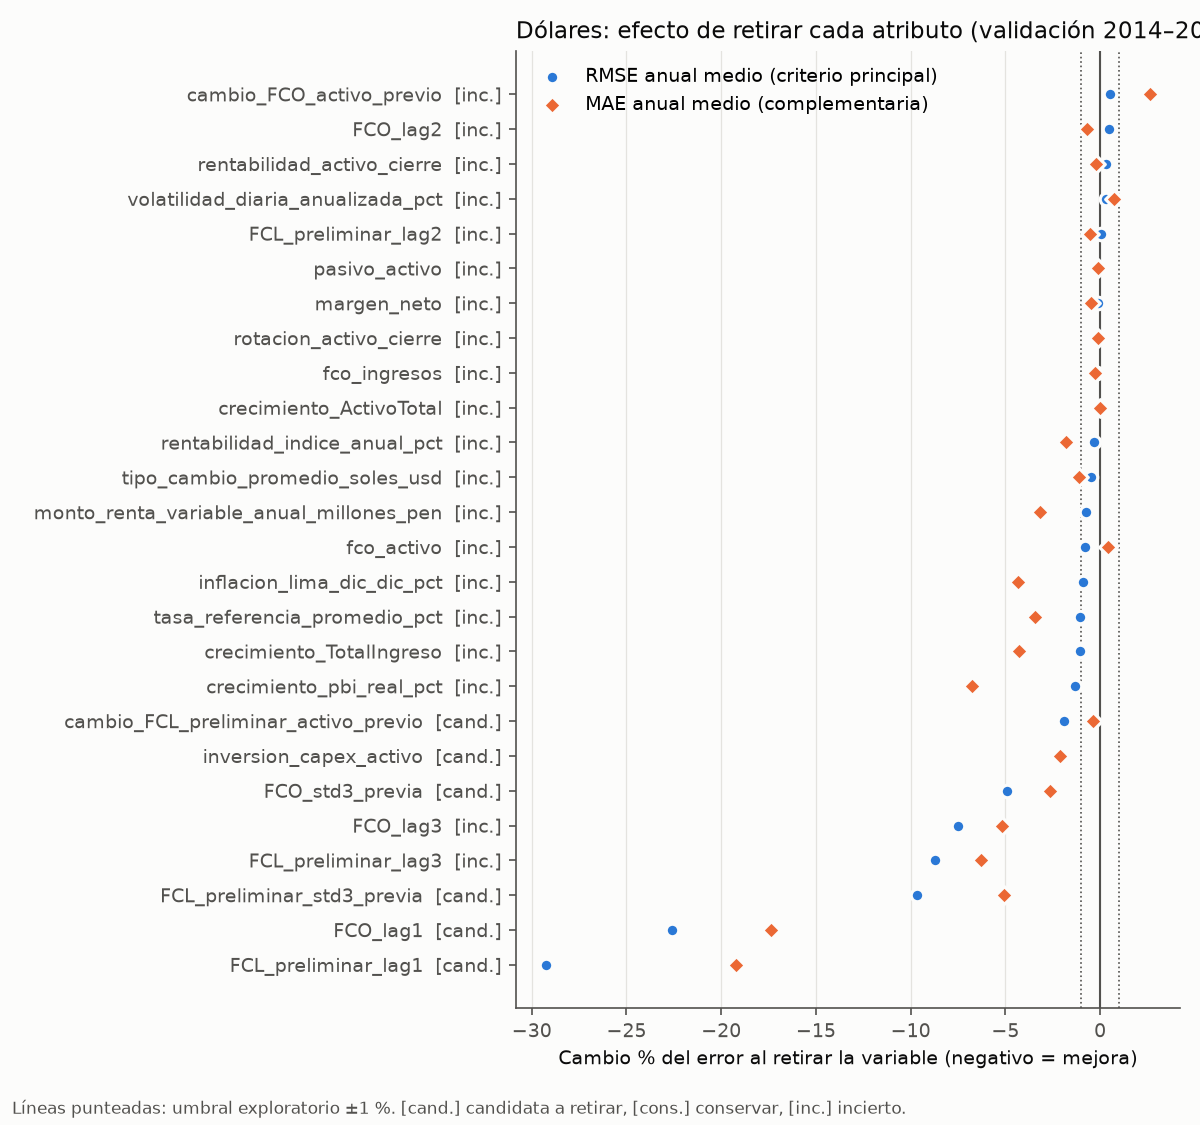

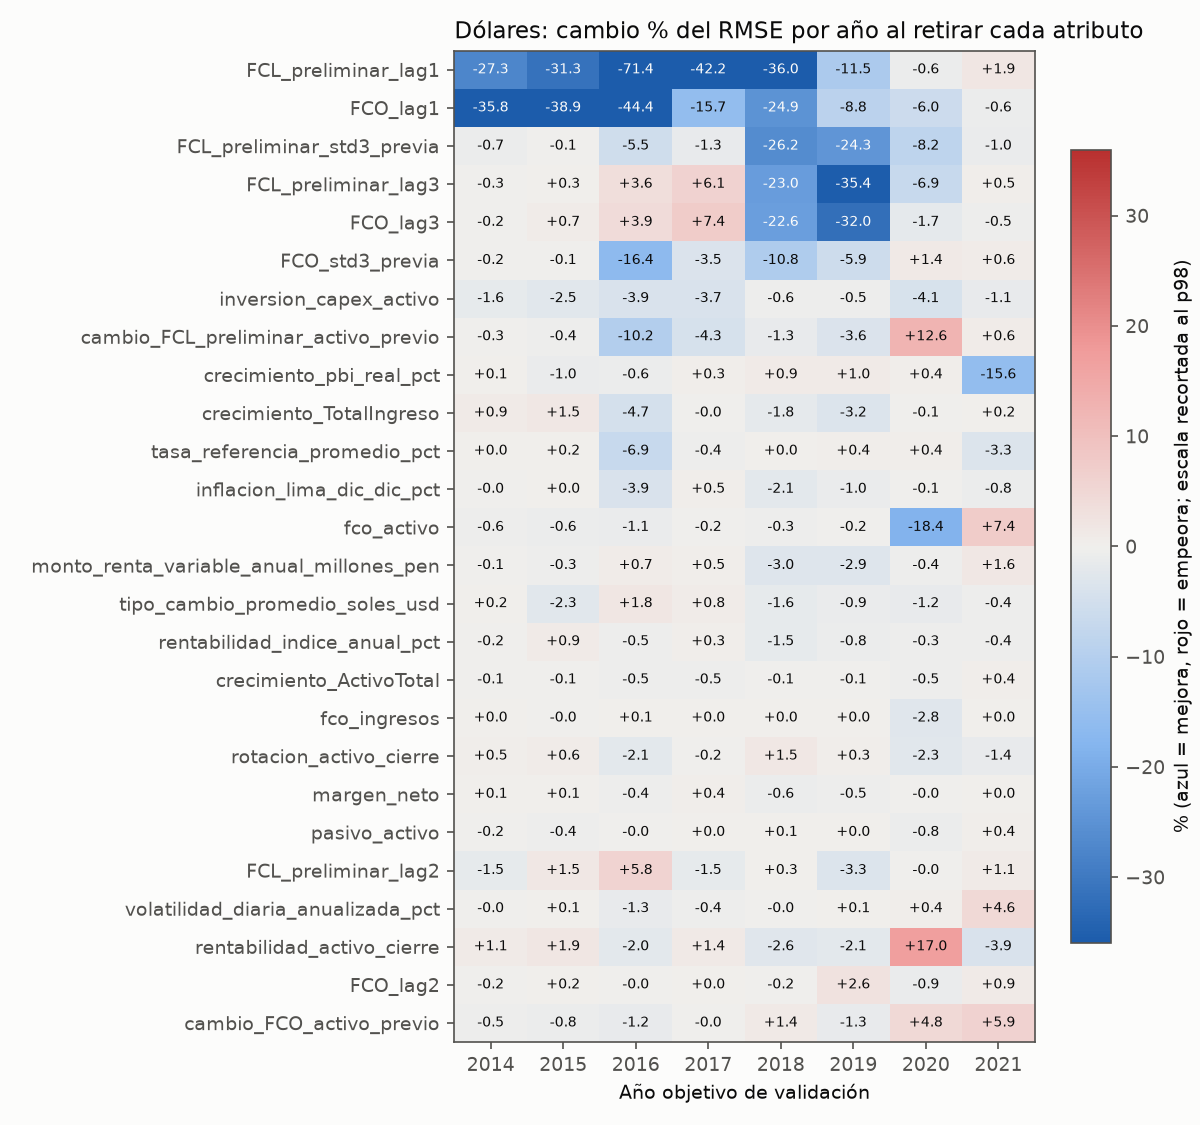

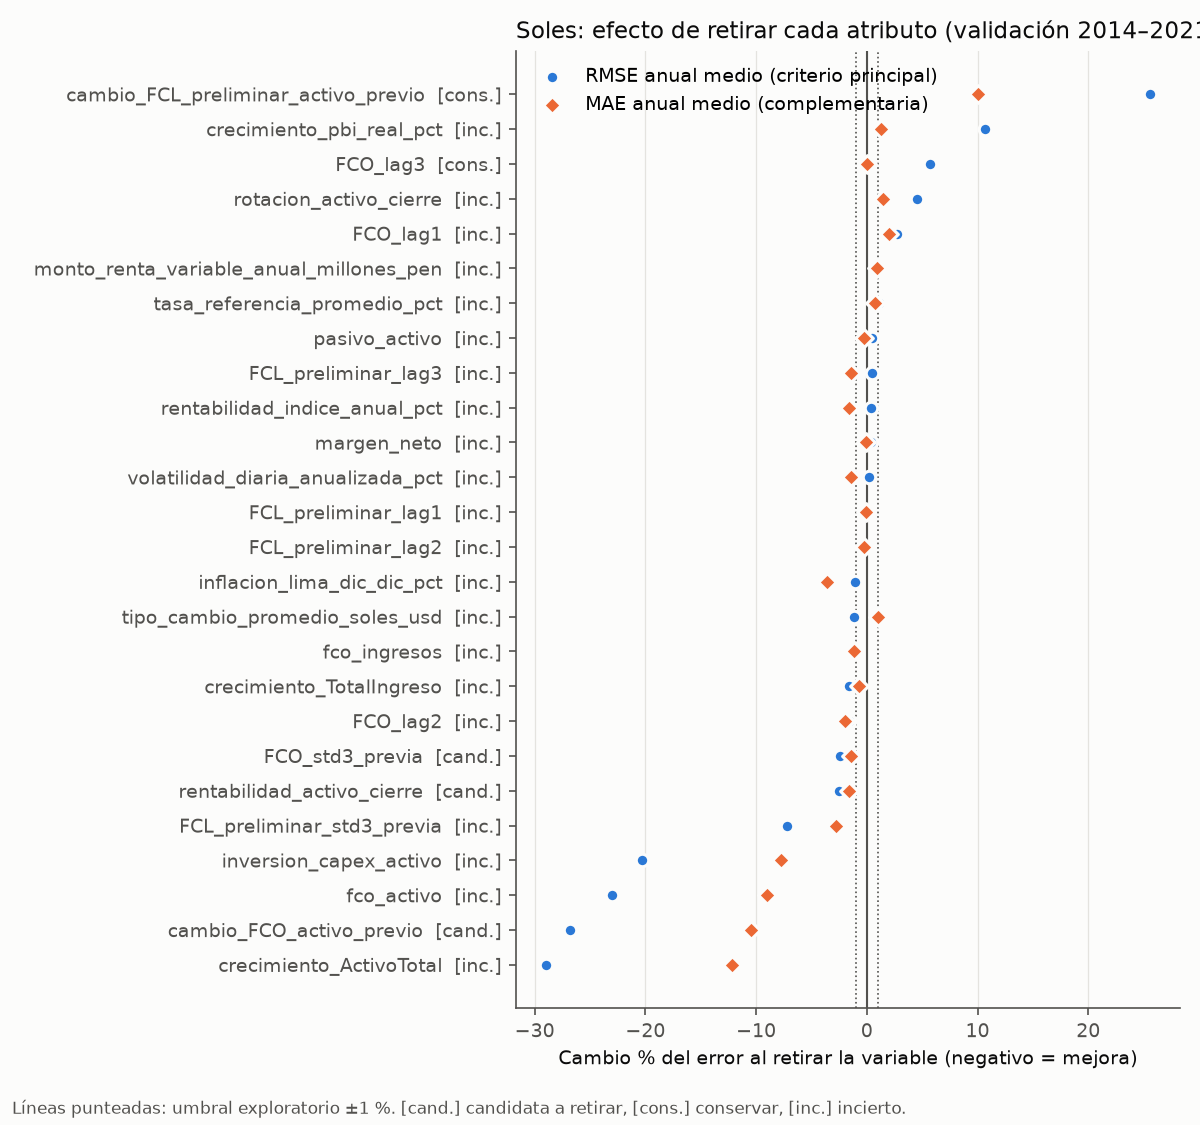

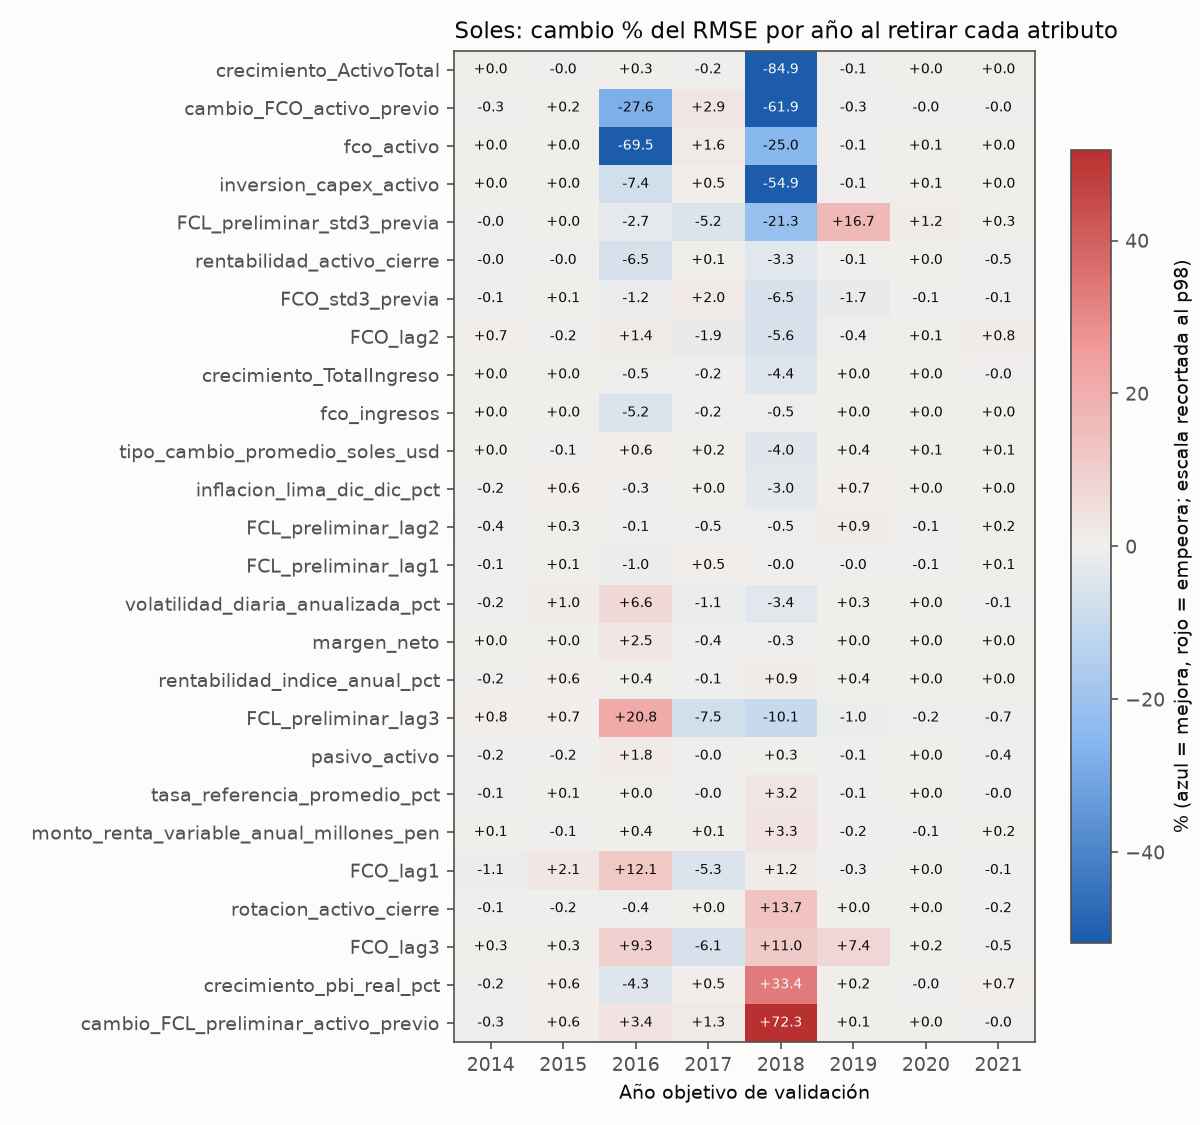

In [10]:
for nombre in ['delta_error_dolares', 'estabilidad_anual_dolares', 'delta_error_soles', 'estabilidad_anual_soles']:
    display(Image(filename=str(ab.OUT / 'graficos' / f'{nombre}.png'), width=720))

Los cambios grandes se concentran en pocos años. Son útiles para formular hipótesis, pero no bastan para retirar variables.

**11. Pruebas automatizadas**
Aislamiento de prueba, separación interna/externa, años futuros, preparación por pliegue, filas comunes, eliminación de atributos y métricas.

In [11]:
suite = unittest.defaultTestLoader.loadTestsFromName('tests.test_ablacion_variables')
def aplanar(s):
    for t in s:
        yield from (aplanar(t) if isinstance(t, unittest.TestSuite) else [t])
resultado = unittest.TextTestRunner(verbosity=1, stream=sys.stdout).run(unittest.TestSuite(t for t in aplanar(suite) if 'notebook' not in t.id()))
assert resultado.wasSuccessful()

.

.

.

.

.

.

... (7 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 16 tests in 34.877s

OK


Las pruebas pasan, incluidos dos controles positivos: perturbar años posteriores no cambia las selecciones pasadas pero sí el año afectado, y una contaminación de entrenamiento con filas de prueba alteraría las predicciones.